# Factory-to-Customer Shipping Route Efficiency Analysis for Nassau Candy Distributor

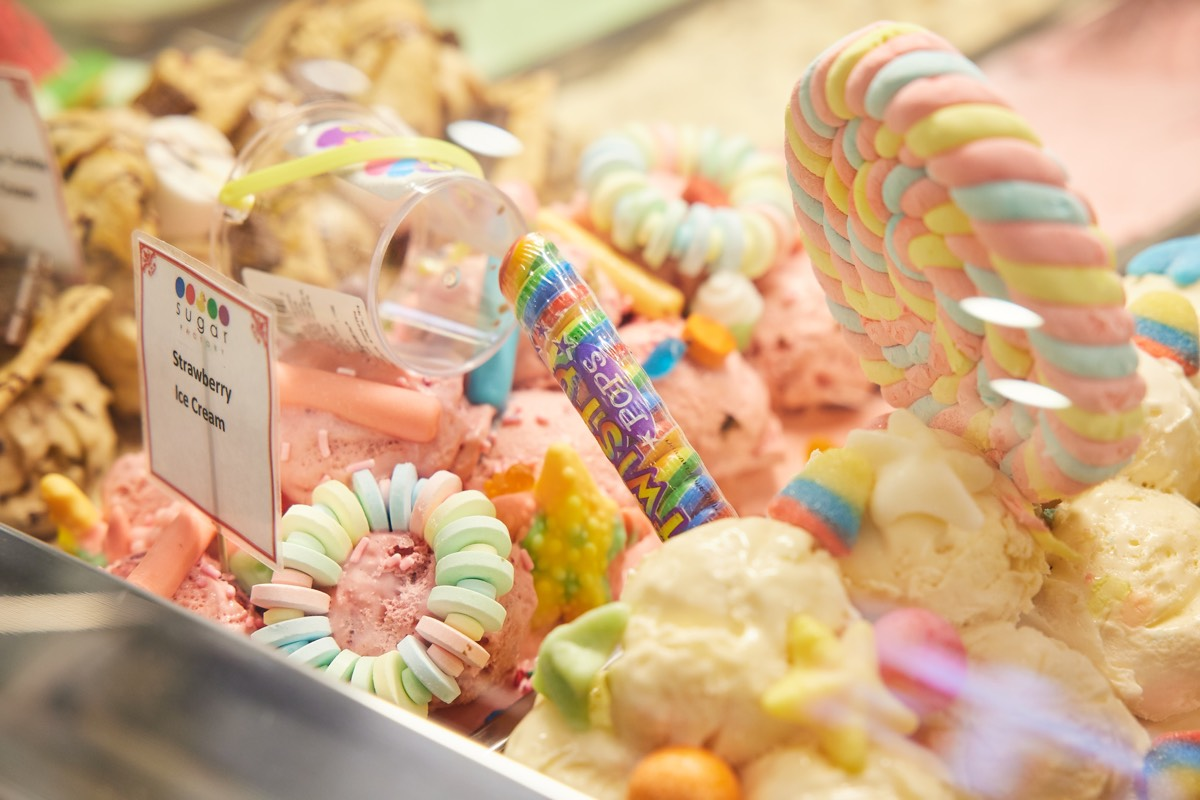

In [135]:
from IPython.display import Image, display

display(Image(filename="D:\Baha-Bay-Waterpark-Dining-Sugar-Factoy-Baha-Mar-Resort-Vacation-Bahamas-10.jpg"))

## Background and Context:
Nassau Candy Distributor operates as a national distributor, shipping products from factories to customers across multiple US regions.
In such operations:

• Shipping efficiency directly affects customer satisfaction
• Delays increase operational cost
• Inefficient routes reduce scalability
Despite having rich order and shipment data, logistics decisions are often made without route-level efficiency intelligence.

### Import Libraries

In [1]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [40]:
import plotly.express as px

In [21]:
import sys
print(sys.version)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


### Load data 

In [22]:
df= pd.read_csv("D:/Nassau Candy Distributor.csv")

In [10]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [23]:
df.sample(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
1655,1656,US-2021-102274-CHO-TRI-54000,21-11-2024,19-05-2027,Standard Class,102274,United States,Richmond,Kentucky,40475,Chocolate,Gulf,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
2025,2026,US-2021-130960-CHO-FUD-51000,30-12-2024,27-06-2027,Standard Class,130960,United States,Taylor,Michigan,48180,Chocolate,Interior,CHO-FUD-51000,Wonka Bar - Fudge Mallows,10.80,3,7.20,3.60
5200,5201,US-2023-169215-CHO-FUD-51000,14-07-2025,07-01-2029,Second Class,169215,United States,Auburn,New York,13021,Chocolate,Atlantic,CHO-FUD-51000,Wonka Bar - Fudge Mallows,32.40,9,21.60,10.80
9711,9712,US-2024-148768-CHO-MIL-31000,30-11-2025,25-05-2030,Second Class,148768,United States,Miami,Florida,33180,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
4187,4188,US-2023-116365-CHO-NUT-13000,03-01-2025,30-06-2028,Standard Class,116365,United States,San Antonio,Texas,78207,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
1268,1269,US-2021-108189-CHO-NUT-13000,02-10-2024,28-03-2027,First Class,108189,United States,Tempe,Arizona,85281,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
8396,8397,US-2024-117646-CHO-MIL-31000,21-08-2025,15-02-2030,Standard Class,117646,United States,Louisville,Colorado,80027,Chocolate,Pacific,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
3669,3670,US-2022-154746-CHO-MIL-31000,14-11-2024,09-05-2028,First Class,154746,United States,Springfield,Virginia,22153,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
3690,3691,US-2022-135685-CHO-NUT-13000,16-11-2024,10-05-2028,Second Class,135685,United States,Milwaukee,Wisconsin,53209,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3406,3407,US-2022-124499-CHO-MIL-31000,09-10-2024,04-04-2028,Standard Class,124499,United States,Detroit,Michigan,48227,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42


### Check dataset dimensions

In [12]:
df.shape

(10194, 18)

In [29]:
df.dtypes

Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID         int64
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Division              str
Region                str
Product ID            str
Product Name          str
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

### Statistical summary

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,10194.0,5097.500000,2942.898656,1.00,2549.25,5097.50,7645.75,10194.0
Customer ID,10194.0,134468.961154,20231.483007,100006.00,117212.00,133550.00,152051.00,192314.0
Sales,10194.0,13.908537,11.341020,1.25,7.20,10.80,18.00,260.0
Units,10194.0,3.791838,2.228317,1.00,2.00,3.00,5.00,14.0
Gross Profit,10194.0,9.166451,6.643740,0.25,4.90,7.47,12.25,130.0
Cost,10194.0,4.742087,5.061647,0.60,2.40,3.60,5.70,130.0


### Check null Value

In [25]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

### Check duplicates

In [92]:
df.duplicated().sum()

np.int64(0)

### Check unique values

In [94]:
for col in df.columns:
    print(col, ":", df[col].nunique())

Row ID : 10194
Order ID : 8549
Order Date : 717
Ship Date : 1338
Ship Mode : 4
Customer ID : 5044
Country/Region : 2
City : 542
State/Province : 59
Postal Code : 654
Division : 3
Region : 4
Product ID : 15
Product Name : 15
Sales : 88
Units : 14
Gross Profit : 121
Cost : 95
Lead Time : 28
Factory : 5
Route (State) : 196
Route (Region) : 20


### Check shipping methods

In [93]:
df['Ship Mode'].value_counts()

Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

### Check regional distribution

In [96]:
df['Region'].value_counts()

Region
Pacific     3253
Atlantic    2986
Interior    2335
Gulf        1620
Name: count, dtype: int64

## Data Cleaning

### Convert dates

In [97]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

### Calculate preliminary lead time

In [98]:
df['Shipping Lead Time'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

df['Shipping Lead Time'].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64

### Identify invalid records

In [100]:
invalid_dates = df[
    (df['Ship Date'] < df['Order Date']) |
    (df['Shipping Lead Time'] < 0)
]

print(invalid_dates)

Empty DataFrame
Columns: [Row ID, Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Country/Region, City, State/Province, Postal Code, Division, Region, Product ID, Product Name, Sales, Units, Gross Profit, Cost, Lead Time, Factory, Route (State), Route (Region), Shipping Lead Time]
Index: []

[0 rows x 23 columns]


In [101]:
df[df['Shipping Lead Time'] > 30]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Product Name,Sales,Units,Gross Profit,Cost,Lead Time,Factory,Route (State),Route (Region),Shipping Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,Wicked Choccy's,Wicked Choccy's → Texas,Wicked Choccy's → Interior,909
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,Wicked Choccy's,Wicked Choccy's → Illinois,Wicked Choccy's → Interior,909
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,Lot's O' Nuts,Lot's O' Nuts → Illinois,Lot's O' Nuts → Interior,909
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,Lot's O' Nuts,Lot's O' Nuts → Illinois,Lot's O' Nuts → Interior,909
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,Wicked Choccy's,Wicked Choccy's → Pennsylvania,Wicked Choccy's → Atlantic,912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,2025-12-30,2030-06-26,Standard Class,143259,United States,New York City,New York,10009,...,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42,1639,Wicked Choccy's,Wicked Choccy's → New York,Wicked Choccy's → Atlantic,1639
10190,10191,US-2024-115427-CHO-NUT-13000,2025-12-30,2030-06-26,Standard Class,115427,United States,Fairfield,California,94533,...,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00,1639,Lot's O' Nuts,Lot's O' Nuts → California,Lot's O' Nuts → Pacific,1639
10191,10192,US-2024-156720-CHO-SCR-58000,2025-12-30,2030-06-26,Standard Class,156720,United States,Loveland,Colorado,80538,...,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,1639,Lot's O' Nuts,Lot's O' Nuts → Colorado,Lot's O' Nuts → Pacific,1639
10192,10193,US-2024-143259-CHO-TRI-54000,2025-12-30,2030-06-26,Standard Class,143259,United States,New York City,New York,10009,...,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10,1639,Wicked Choccy's,Wicked Choccy's → New York,Wicked Choccy's → Atlantic,1639


## Feature Engineering

### Create date features

In [102]:
df['Order Year'] = df['Order Date'].dt.year

df['Order Month'] = df['Order Date'].dt.month_name()

df['Order Quarter'] = (
    df['Order Date'].dt.to_period('Q').astype(str)
)

### Create shipping categories

In [103]:
def shipping_category(days):

    if days <= 2:
        return 'Fast'

    elif days <= 5:
        return 'Medium'

    else:
        return 'Slow'

In [ ]:
### Create order-level dataset

In [104]:
order_df = df.drop_duplicates(
    subset=['Order ID']
).copy()

print("Total Shipments:", len(order_df))

Total Shipments: 8549


## Exploratory Data Analysis (EDA)

###  What is the total number of shipments?

In [111]:
total_shipments = order_df['Order ID'].nunique()

print("Total Shipments:", total_shipments)

Total Shipments: 8549


### Business Insight:

The company processed 8,549 unique orders across the available dataset. Therefore, shipment analysis should use unique Order IDs rather than counting individual product rows.

### Recommendation:

Management should monitor shipment volume at the order level to avoid overstating logistics activity.

### What is the average shipping lead time?

In [122]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y'
)

df['Shipping Lead Time'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

average_lead_time = df['Shipping Lead Time'].mean()

print("Average Shipping Lead Time:", average_lead_time)

Average Shipping Lead Time: 1320.8418677653522


### Important data-quality finding:

The calculated average is approximately 1,321 days.

This is clearly suspicious for a shipping dataset.
- Order dates range from January 2024 to December 2025.
- Shipping dates range from June 2026 to June 2030.
- All 10,194 rows have calculated lead times exceeding 365 days.
We should not interpret this as actual shipping performance.

### Business Insight:

The shipment-date information contains a major inconsistency that prevents reliable measurement of shipping efficiency.


### Recommendation:
Before making logistics decisions, management should validate the original shipping records and obtain corrected shipment dates. We should not artificially change dates to make the results look realistic.

### Which region has the highest shipment volume?

Region
Pacific     2744
Atlantic    2476
Interior    1979
Gulf        1350
Name: Order ID, dtype: int64


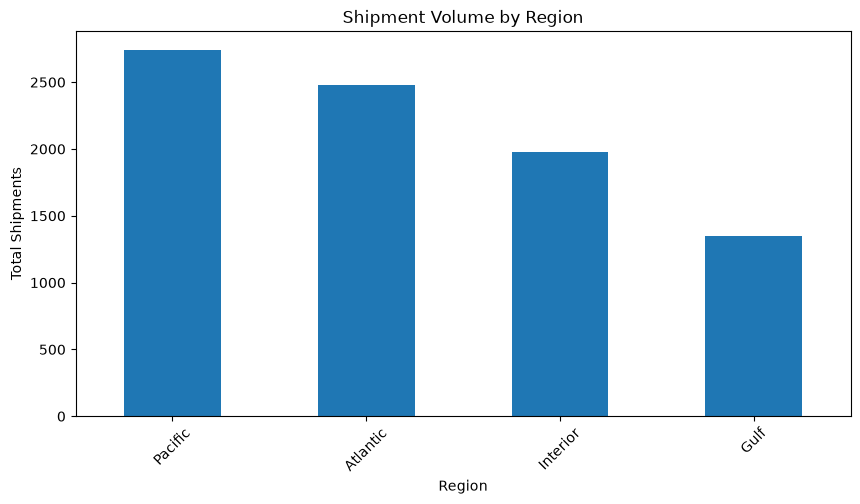

In [119]:
region_shipments = (
    order_df.groupby('Region')['Order ID']
    .nunique()
    .sort_values(ascending=False)
)

print(region_shipments)

region_shipments.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Shipment Volume by Region')
plt.xlabel('Region')
plt.ylabel('Total Shipments')
plt.xticks(rotation=45)
plt.show()

### Business Insights:
1. Pacific has the highest shipment volume.
2. Atlantic is the second-largest region.
3. Gulf has the lowest shipment volume.
4. Pacific and Atlantic together account for approximately 61% of orders.
### Recommendations:
- Prioritize logistics capacity planning in Pacific and Atlantic.
- Monitor warehouse inventory and transportation capacity in high-volume regions.
- Investigate whether Gulf has lower demand or limited distribution coverage.
- Allocate operational resources according to shipment demand.

### Which 10 states have the highest shipment volume?

State/Province
California        1686
New York           942
Texas              833
Pennsylvania       487
Illinois           433
Washington         432
Ohio               392
Florida            319
North Carolina     216
Michigan           209
Name: Order ID, dtype: int64


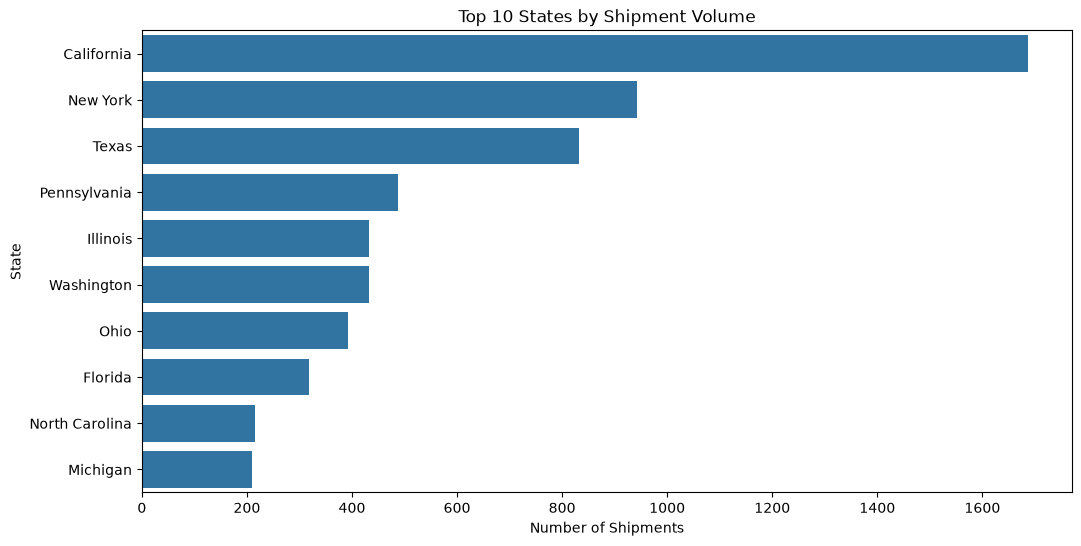

In [125]:
state_shipments = (
    order_df.groupby('State/Province')['Order ID']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print(state_shipments)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=state_shipments.values,
    y=state_shipments.index
)

plt.title('Top 10 States by Shipment Volume')
plt.xlabel('Number of Shipments')
plt.ylabel('State')

plt.show()


### Business Insights:
- California is the largest shipment destination.
- New York and Texas are the next two major markets.
- The top three states account for approximately 40.5% of all orders.
### Recommendations:
1. Prioritize transportation capacity for California, New York and Texas.
2. Maintain sufficient inventory availability for high-demand locations.
3. Monitor shipment backlogs in states receiving large order volumes.
4. Evaluate whether regional distribution centres could improve service efficiency.

### Which shipping mode is most frequently used?

Ship Mode
Standard Class    5142
Second Class      1653
First Class       1312
Same Day           442
Name: count, dtype: int64


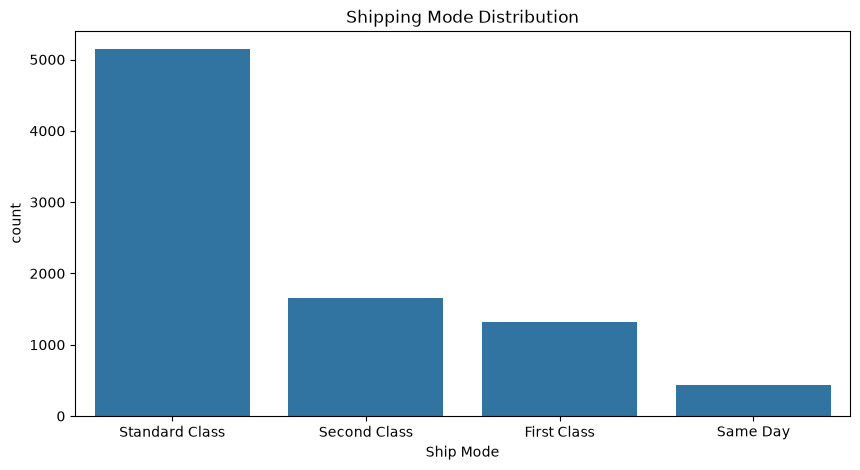

In [127]:
shipping_mode = order_df['Ship Mode'].value_counts()

print(shipping_mode)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=order_df,
    x='Ship Mode',
    order=order_df['Ship Mode'].value_counts().index
)

plt.title('Shipping Mode Distribution')

plt.show()


### Business Insights:
- Standard Class accounts for approximately 60% of shipments.
- Second Class accounts for approximately 19%.
- First Class accounts for approximately 15%.
- Same Day accounts for approximately 5%.
Standard Class is the dominant shipping method.

### Recommendations:
- Review whether Standard Class capacity is sufficient for the large shipment volume.
- Evaluate the business need for expedited shipping.
- Compare transportation costs against validated shipping performance.
- Avoid assuming that expensive shipping modes are necessarily faster without reliable shipment data.

### What is the highest average shipping lead time?

In [126]:
state_performance = (
    order_df.groupby('State/Province')
    .agg(
        Total_Shipments=('Order ID', 'nunique'),
        Average_Lead_Time=('Shipping Lead Time', 'mean')
    )
    .reset_index()
)

state_performance = state_performance[
    state_performance['Total_Shipments'] >= 30
]

state_performance = state_performance.sort_values(
    'Average_Lead_Time',
    ascending=False
)

print(state_performance.head(10))

   State/Province  Total_Shipments  Average_Lead_Time
33     New Mexico               34        1424.352941
50      Tennessee              151        1387.370861
14        Indiana              123        1368.585366
55     Washington              432        1364.631944
21       Maryland               80        1364.525000
46   Rhode Island               46        1352.152174
7     Connecticut               74        1351.932432
32     New Jersey              108        1351.518519
26       Missouri               56        1338.535714
24      Minnesota               75        1337.280000


### Business Insight:

These values are too large to represent credible shipping durations. Although Interior ranks highest numerically, we cannot conclude that it is the slowest region.

### Recommendation:

Validate the shipment dates before prioritizing regional logistics improvements.

### Compare average shipping lead time by shipping mode.

In [128]:
ship_mode_performance = (
    order_df.groupby('Ship Mode')
    .agg(
        Total_Shipments=('Order ID', 'nunique'),
        Average_Lead_Time=('Shipping Lead Time', 'mean'),
        Median_Lead_Time=('Shipping Lead Time', 'median')
    )
    .reset_index()
)

print(ship_mode_performance)

        Ship Mode  Total_Shipments  Average_Lead_Time  Median_Lead_Time
0     First Class             1312        1337.209604            1272.0
1        Same Day              442        1328.009050            1269.0
2    Second Class             1653        1320.456745            1273.0
3  Standard Class             5142        1317.050370            1274.0


### Business Insight:

The preliminary averages cannot establish which shipping method is fastest because of the date inconsistencies.

### Recommendation:

After correcting dates, compare average and median lead times across all four shipping methods. This will help management understand the actual cost-time trade-off.

### Which region-state combinations have the highest shipment volume?

In [130]:
route_analysis = (
    order_df.groupby(['Region', 'State/Province'])
    .agg(
        Total_Shipments=('Order ID', 'nunique'),
        Average_Lead_Time=('Shipping Lead Time', 'mean')
    )
    .reset_index()
)

route_analysis = route_analysis.sort_values(
    'Total_Shipments',
    ascending=False
)

print(route_analysis.head(15))

      Region  State/Province  Total_Shipments  Average_Lead_Time
48   Pacific      California             1686        1319.097865
9   Atlantic        New York              942        1323.342887
43  Interior           Texas              833        1312.238896
14  Atlantic    Pennsylvania              487        1320.429158
31  Interior        Illinois              433        1321.545035
57   Pacific      Washington              432        1364.631944
12  Atlantic            Ohio              392        1327.854592
22      Gulf         Florida              319        1313.347962
27      Gulf  North Carolina              216        1329.050926
36  Interior        Michigan              209        1311.779904
46   Pacific         Arizona              190        1307.957895
30      Gulf        Virginia              185        1231.567568
23      Gulf         Georgia              151        1336.099338
29      Gulf       Tennessee              151        1387.370861
49   Pacific        Color

### Business objective:

Identify high-volume geographical combinations.

Business Insight:

This analysis can help management identify important customer markets and understand where logistics resources are most heavily utilized.

### Recommendation:

Prioritize high-volume destinations for capacity planning and inventory availability.

### Identify high-volume and potentially inefficient locations.

In [133]:
volume_threshold = route_analysis[
    'Total_Shipments'
].median()

lead_threshold = route_analysis[
    'Average_Lead_Time'
].median()

def classify_route(row):

    if (
        row['Total_Shipments'] >= volume_threshold
        and row['Average_Lead_Time'] >= lead_threshold
    ):
        return 'High Volume - High Lead Time'

    elif (
        row['Total_Shipments'] >= volume_threshold
    ):
        return 'High Volume - Lower Lead Time'

    elif (
        row['Average_Lead_Time'] >= lead_threshold
    ):
        return 'Low Volume - High Lead Time'

    else:
        return 'Low Volume - Lower Lead Time'

route_analysis['Performance Category'] = (
    route_analysis.apply(classify_route, axis=1)
)

print(
    route_analysis[
        route_analysis['Performance Category']
        == 'High Volume - High Lead Time'
    ]
)

      Region  State/Province  Total_Shipments  Average_Lead_Time  \
9   Atlantic        New York              942        1323.342887   
14  Atlantic    Pennsylvania              487        1320.429158   
31  Interior        Illinois              433        1321.545035   
57   Pacific      Washington              432        1364.631944   
12  Atlantic            Ohio              392        1327.854592   
27      Gulf  North Carolina              216        1329.050926   
23      Gulf         Georgia              151        1336.099338   
29      Gulf       Tennessee              151        1387.370861   
49   Pacific        Colorado              140        1330.271429   
32  Interior         Indiana              123        1368.585366   
24      Gulf        Kentucky              112        1335.196429   
8   Atlantic      New Jersey              108        1351.518519   
44  Interior       Wisconsin               91        1333.549451   
4   Atlantic        Maryland               80   

### Business Insights:

This framework identifies geographical combinations requiring investigation.

### Recommendations:
#### Category---------------------- Recommended Action
- High Volume - High Lead Time	--Highest investigation priority
- High Volume - Lower Lead Time --	Maintain operational capacity
- Low Volume - High Lead Time --	Investigate service coverage
- Low Volume - Lower Lead Time	-- Monitor performance


The classification becomes operationally meaningful only after correcting the date data.

### Count unique orders by state

State/Province
California        1686
New York           942
Texas              833
Pennsylvania       487
Illinois           433
Washington         432
Ohio               392
Florida            319
North Carolina     216
Michigan           209
Name: Order ID, dtype: int64


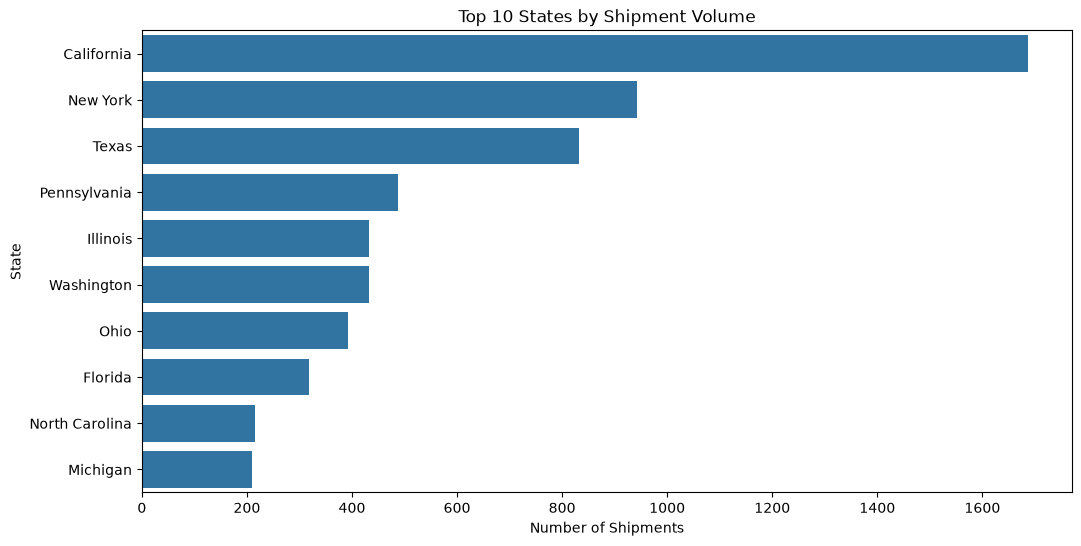

In [118]:

state_shipments = (
    df.groupby('State/Province')['Order ID']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print(state_shipments)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=state_shipments.values,
    y=state_shipments.index
)

plt.title('Top 10 States by Shipment Volume')
plt.xlabel('Number of Shipments')
plt.ylabel('State')

plt.show()

## Business Insight
- California has the highest shipment volume.
- New York and Texas are the second and third largest shipment destinations.
- Shipment demand is concentrated in a relatively small number of states.

## Business Recommendation
- Management should prioritize monitoring shipment capacity and operational performance in California, New York and Texas.

## Final Recomandation 

Based on the preliminary analysis, the following recommendations can help management improve shipping operations, resource allocation and overall logistics efficiency.
1. Optimize High-Volume Regions: Pacific and Atlantic have the highest shipment volumes. Management should prioritize transportation capacity, inventory availability and logistics resources in these regions.
2. Focus on High-Demand States: California, New York and Texas account for a significant share of total orders. The company should closely monitor shipment capacity and operational performance in these states.
3. Improve Shipping Mode Allocation: Standard Class accounts for approximately 60% of shipments. Management should evaluate whether the current shipping-mode allocation meets customer expectations and operational requirements.
4. Investigate Regional Performance: Conduct further investigations into regions and states with unusually high calculated shipping lead times after correcting the date inconsistencies.
5. Strengthen Data Quality Management: The dataset contains inconsistent order and shipment dates. The company should establish proper date validation procedures to ensure accurate shipping performance measurement.
6. Introduce Route-Level Monitoring: Maintain detailed records of factory locations, dispatch locations and customer destinations to identify genuinely inefficient transportation routes.
7. Monitor Shipment Performance Regularly: Develop an interactive dashboard to track shipment volume, average shipping lead time, regional performance and shipping-mode distribution.
8. Improve Geographic Resource Allocation: Allocate logistics resources according to regional shipment demand. High-volume destinations should receive appropriate transportation and inventory support.
9. Collect Actual Delivery Information: Record actual delivery dates and expected delivery dates to measure on-time delivery performance and identify genuine customer service issues.
10. Implement Data-Driven Logistics Decisions: Use regular performance analysis to identify operational bottlenecks, monitor improvement initiatives and support better logistics planning.

## Overall Business Conclusion
The analysis highlights that shipment volume is concentrated in regions such as Pacific and Atlantic, with California, New York and Texas representing major customer destinations. Standard Class is the most frequently used shipping method.

However, inconsistencies in shipment dates and the absence of factory locations and actual delivery dates limit the ability to measure genuine route efficiency and delivery delays.

Therefore, Nassau Candy Distributor should prioritize data quality improvement, regional capacity planning and shipment performance monitoring before implementing major route optimization strategies.